In [1]:
import os, glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'therapeutic', 'vaccines')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth_data, 'results', 'therapeutic', 'vaccines')
pth_fig = os.path.join(pth, 'figures', 'therapeutic', 'vaccines')

In [3]:
# load CZ CELLxGENE gene expression (pseudobulk)
fn = os.path.join(pth_in, 'CELLxGENE_pbulk.csv')
df = pd.read_csv(fn, index_col = [0, 1])
df = df.sub(df.mean(axis = 1), axis = 0)

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
df_res = pd.DataFrame(index = df.index)
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.hsapiens.drop_duplicates()
        g = g.loc[g.isin(df.columns)].copy()
        df_res[src] = df[g].mean(axis = 1)
        print(src, g.size, df.shape[1])
df_res.to_csv(os.path.join(pth_out, 'signatures.csv'))

GSE162534 81 238
GSE229103 98 238
rRNAModifications 103 238


In [5]:
c_dict = {
    'GSE162534'         : plt.cm.tab20c(12),
    'GSE229103'         : plt.cm.tab20c(8),
    'rRNAModifications' : plt.cm.tab20c(4)}

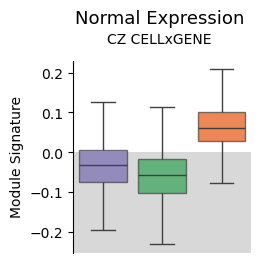

In [6]:
# plot signatures
fig, ax = plt.subplots(1, 1, figsize = (2.3, 2.5))
sns.boxplot(df_res, palette = c_dict,
            showfliers = False,
            boxprops = {'alpha' : .7},
            saturation = 1, ax = ax)
ylim = ax.get_ylim()
ax.axhspan(ylim[0], 0, facecolor = 'gray', alpha = .3)
ax.set_ylim(ylim); ax.set_xticks([])
ax.set_ylabel('Module Signature')
fig.suptitle('Normal Expression', size = 13, y = 1.085)
fig.text(.5, .95, 'CZ CELLxGENE', ha = 'center')
for sp in ('top', 'bottom', 'right'):
    ax.spines[sp].set_visible(False)
fn = os.path.join(pth_fig, 'signatures.pdf')
plt.savefig(fn, bbox_inches = 'tight')